In [1]:
import pandas as pd
import pylab as pl
import numpy as np
import scipy.optimize as opt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')  # Ignora las advertencias durante la ejecución

In [3]:
data = pd.read_csv("recursos_humanos.csv")  # Carga el archivo CSV
data  # Muestra los datos

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [5]:
data = pd.get_dummies(data, columns=["sales", "salary"], dtype=int)
data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,...,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14995,0.37,0.48,2,160,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14996,0.37,0.53,2,143,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14997,0.11,0.96,6,280,4,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0


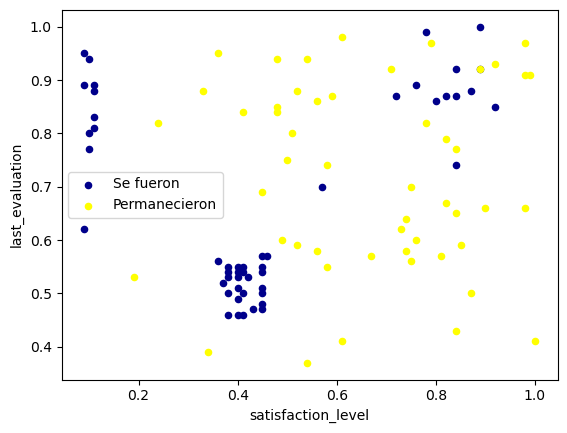

In [7]:
ax = data[data["left"] == 1][0:50].plot(kind="scatter", x="satisfaction_level"
                    , y="last_evaluation", color="DarkBlue", label="Se fueron");
ax = data[data["left"] == 0][0:50].plot(kind="scatter", x="satisfaction_level"
                    , y="last_evaluation", color="Yellow", label="Permanecieron",ax=ax);
plt.show()

In [9]:
# Pre-Procesamiento de datos y selección
data.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
sales_IT                   int32
sales_RandD                int32
sales_accounting           int32
sales_hr                   int32
sales_management           int32
sales_marketing            int32
sales_product_mng          int32
sales_sales                int32
sales_support              int32
sales_technical            int32
salary_high                int32
salary_low                 int32
salary_medium              int32
dtype: object

In [11]:
feature_df = data.drop(["left"], axis=1)
X = np.asarray(feature_df)
X[0:5]

array([[3.80e-01, 5.30e-01, 2.00e+00, 1.57e+02, 3.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        1.00e+00, 0.00e+00],
       [8.00e-01, 8.60e-01, 5.00e+00, 2.62e+02, 6.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 1.00e+00],
       [1.10e-01, 8.80e-01, 7.00e+00, 2.72e+02, 4.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 1.00e+00],
       [7.20e-01, 8.70e-01, 5.00e+00, 2.23e+02, 5.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        1.00e+00, 0.00e+00],
       [3.70e-01, 5.20e-01, 2.00e+00, 1.59e+02, 3.00e+00, 0.00e+00,


In [13]:
data["left"] = data["left"].astype("int")
y = np.asarray(data["left"])
y[0:5]

array([1, 1, 1, 1, 1])

In [15]:
# Creación de grupos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                test_size=0.2, random_state=4)
print("Grupo de entrenamiento", X_train.shape, y_train.shape)
print("Grupo de prueba", X_test.shape, y_test.shape)

Grupo de entrenamiento (11999, 20) (11999,)
Grupo de prueba (3000, 20) (3000,)


# Modelación con SVM
Opciones de Kernel (Transformaciones):

1. Linear
2. Polynomial
3. Radial Basis function (RBF)
4. Sigmoid

In [17]:
from sklearn import svm
clf = svm.SVC(kernel="rbf")
clf.fit(X_train, y_train)

SVC()

In [19]:
# Predicción para la base de prueba
yhat = clf.predict(X_test)
yhat[0:5]

array([0, 0, 0, 0, 0])

In [21]:
# Creación de matriz de confusión
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[2287,    0],
       [ 669,   44]], dtype=int64)

In [23]:
y_test

array([0, 1, 0, ..., 0, 1, 1])

In [25]:
yhat

array([0, 0, 0, ..., 0, 0, 0])

In [27]:
z = y_test - yhat
z

array([0, 1, 0, ..., 0, 1, 1])

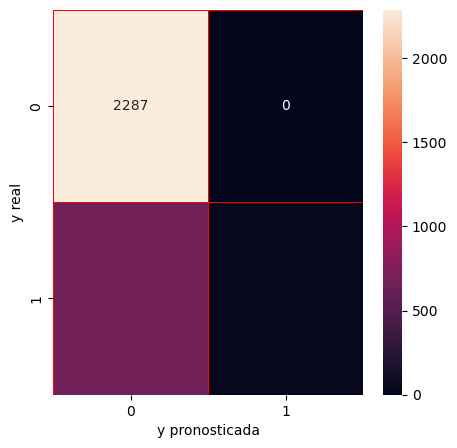

In [29]:
# Visualización de la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

# Estadísticas de desempeño

In [31]:
from sklearn.metrics import classification_report
cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.77      1.00      0.87      2287
           1       1.00      0.06      0.12       713

    accuracy                           0.78      3000
   macro avg       0.89      0.53      0.49      3000
weighted avg       0.83      0.78      0.69      3000



# Determinación de niveles de precisión (Precision)
La Precisión ("Precision") = Porcentaje de predicciones correctas relativas al total de predicciones

* El total se calcular por columna
* Se contesta a la pregunta: ¿Qué porcentaje de las veces que hacemos un pronóstico de cierto tipo éste es correcto?

In [33]:
PrecisionPermanecieron = cm[0,0] / (cm[0,0] + cm[1,0])
PrecisionPermanecieron

0.773680649526387

In [35]:
PrecisionSeFueron = cm[1,1] / (cm[1,1] + cm[0,1])
PrecisionSeFueron

1.0

# Determinación de niveles de Recuperación (Recall)
La Recuperación (Recall) = Porcentaje de predicciones correctas relativas al total de valores reales

* El total se calcular por renglón
* Se contesta a la pregunta: ¿Qué porcentaje de las veces que se tiene un valor es de identificarlo?

In [37]:
RecallPermanecieron = cm[0,0] / (cm[0,0] + cm[0,1])
RecallPermanecieron

1.0

In [39]:
RecallSeFueron = cm[1,1] / (cm[1,0] + cm[1,1])
RecallSeFueron

0.061711079943899017

# Determinación del Score F1
F1 Score = Media armónica ponderada de la precisión y la recuperación. Cuanto más se acerque a 1, mejor será el modelo

* F1 Score = 2 * (Precision * Recall) / (Precision + Recall)

In [41]:
F1Permanecieron = 2 * (PrecisionPermanecieron * RecallPermanecieron) / (PrecisionPermanecieron + RecallPermanecieron)
F1Permanecieron

0.8724012969673851

In [43]:
F1SeFueron = 2 * (PrecisionSeFueron * RecallSeFueron) / (PrecisionSeFueron + RecallSeFueron)
F1SeFueron

0.11624834874504625

# Determinación de soportes
Soporte = Número de observaciones que pertenecen en forma real a cada clase posible (Total por renglón)

In [45]:
SoportePermanecieron = cm[0,0] + cm[0,1]
SoportePermanecieron

2287

In [47]:
SoporteSeFueron = cm[1,0] + cm[1,1]
SoporteSeFueron

713

# Determinación de la Precisión Global (Accuracy)
Accuracy = Porcentaje de predicciones correctas

In [49]:
Correctos = cm[0,0] + cm[1,1]
Incorrectos = cm[0,1] + cm[1,0]
PrecisionGlobal = Correctos / (Correctos + Incorrectos)
PrecisionGlobal

0.777

# Promedios simples por indicador (Macro Average)
Promedio simples por Precisión, Recuperación y F1 Score

In [51]:
MacroAvgPrecision = (PrecisionPermanecieron + PrecisionSeFueron) / 2
MacroAvgPrecision

0.8868403247631935

In [53]:
MacroAvgRecall = (RecallPermanecieron + RecallSeFueron) / 2
MacroAvgRecall

0.5308555399719495

In [55]:
MacroF1Score = (F1Permanecieron + F1SeFueron) / 2
MacroF1Score

0.4943248228562157

# Promedios ponderados por indicador (Weighted Average)
Promedios ponderados de acuerdo a soportes por indicador

In [57]:
PesoPermanecieron = SoportePermanecieron / (SoportePermanecieron + SoporteSeFueron)
PesoSeFueron = SoporteSeFueron / (SoportePermanecieron + SoporteSeFueron)

In [59]:
WAvgPrecision = PrecisionPermanecieron * PesoPermanecieron + PrecisionSeFueron * PesoSeFueron
WAvgPrecision

0.8274692151556158

In [61]:
WAvgRecall = RecallPermanecieron * PesoPermanecieron + RecallSeFueron * PesoSeFueron
WAvgRecall

0.777

# Prueba de SVM con kernel Lineal

In [63]:
clf = svm.SVC(kernel='linear')
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

#confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[2147,  140],
       [ 522,  191]], dtype=int64)

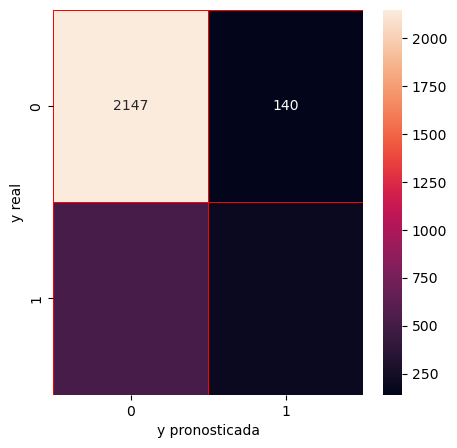

In [65]:
# Visualización de la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [67]:
from sklearn.metrics import classification_report
# import itertools

cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
# np.set_printoptions(precision=2)

print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.80      0.94      0.87      2287
           1       0.58      0.27      0.37       713

    accuracy                           0.78      3000
   macro avg       0.69      0.60      0.62      3000
weighted avg       0.75      0.78      0.75      3000



# Prueba de SVM con kernel Polinomial

In [69]:
clf = svm.SVC(kernel='poly')
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

#confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[2287,    0],
       [ 713,    0]], dtype=int64)

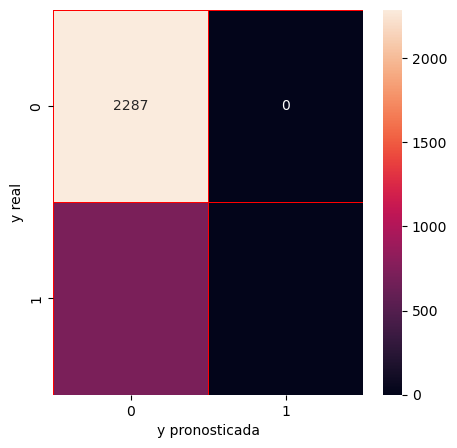

In [71]:
# Visualización de la matriz de confusión
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [73]:
from sklearn.metrics import classification_report

cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])

print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.76      1.00      0.87      2287
           1       0.00      0.00      0.00       713

    accuracy                           0.76      3000
   macro avg       0.38      0.50      0.43      3000
weighted avg       0.58      0.76      0.66      3000



# Prueba de SVM con kernel Sigmoide

In [75]:
clf = svm.SVC(kernel='sigmoid')
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

#confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[1885,  402],
       [ 507,  206]], dtype=int64)

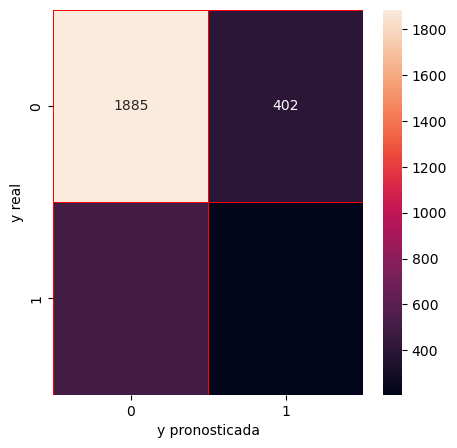

In [77]:
# Visualización de la matriz de confusión
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [79]:
from sklearn.metrics import classification_report

cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])

print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.79      0.82      0.81      2287
           1       0.34      0.29      0.31       713

    accuracy                           0.70      3000
   macro avg       0.56      0.56      0.56      3000
weighted avg       0.68      0.70      0.69      3000



In [81]:
# Modelo SVM con kernel Lineal
clf = svm.SVC(kernel='linear')
clf.fit(X_train, y_train)

SVC(kernel='linear')

In [83]:
empleado = pd.read_csv("1 empleado.csv")
empleado

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.87,1,5,242,5,0,1,0,sales,low


In [85]:
empleado = empleado.drop(["left"], axis=1)

In [87]:
empleado = pd.get_dummies(empleado, columns=["sales", "salary"], dtype=int)
empleado

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_sales,salary_low
0,0.87,1,5,242,5,0,0,1,1


In [89]:
empleado = empleado.reindex(columns=feature_df.columns, fill_value=0)

X_empleado = np.asarray(empleado)
X_empleado

array([[  0.87,   1.  ,   5.  , 242.  ,   5.  ,   0.  ,   0.  ,   0.  ,
          0.  ,   0.  ,   0.  ,   0.  ,   0.  ,   0.  ,   1.  ,   0.  ,
          0.  ,   0.  ,   1.  ,   0.  ]])

In [91]:
# Predicción para el empleado
pronostico = clf.predict(X_empleado)
pronostico

array([0])

# ¿Cuál resultó ser el modelo predictivo más adecuado? Explique su razonamiento.

El modelo predictivo más adecuado fue el de Máquinas de Soporte Vectorial con kernel lineal. Esto se debe a que obtuvo la mayor precisión global (accuracy) de aproximadamente 78% y el mejor promedio macro de F1 (Macro F1 = 0.62) en comparación con los otros kernels.

Además, presentó un mejor desempeño al identificar a los empleados que abandonaron la empresa (clase 1), con un F1 de 0.37, mientras que RBF obtuvo 0.12, polinomial 0.00 y sigmoide 0.31. Aunque el kernel sigmoide tuvo un recall ligeramente superior para esta clase, el lineal presentó un mejor equilibrio general entre precisión y recuperación.

Por estas razones, se seleccionó el kernel lineal como el modelo más adecuado para realizar las predicciones.

# ¿Qué resultado pronosticaría para un empleado con los siguientes indicadores?

Para el empleado proporcionado, se utilizaron los siguientes indicadores: nivel de satisfacción de 0.87, última evaluación de 1, cinco proyectos, 242 horas mensuales, cinco años de antigüedad, sin accidentes laborales, sin promociones, departamento de ventas y salario bajo.

Al introducir estos datos en el modelo SVM con kernel lineal, se obtuvo el resultado 0, lo que significa que el modelo pronostica que el empleado permanecerá en la empresa.

Por lo tanto, de acuerdo con el modelo seleccionado, se espera que el empleado no abandone la organización.